# Nguyễn Thành Trí - MSSV: 6451071079

## Phần 1 - Bài 1 (Trang 15-17): Lập trình tiền xử lý dữ liệu Titanic

Tập dữ liệu: `titanic.csv`
Thực hiện tiền xử lý dữ liệu hành khách tàu Titanic gồm 8 câu hỏi từ Câu 1 đến Câu 8.

### Câu 1: Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính
- Đọc dữ liệu từ file `titanic.csv` (xác định ký tự `?` là giá trị rỗng `NaN`).
- Đưa tên cột về chữ thường và chuyển đổi kiểu dữ liệu thích hợp.
- Hiển thị 5 dòng đầu tiên (`head()`), cấu trúc dữ liệu (`info()`) và tóm tắt thống kê cơ bản (`describe()`).

In [1]:
# Nguyễn Thành Trí - 6451071079
# Bài 1 (Trang 15-17) - Câu 1: Nhập dữ liệu và thống kê cơ bản

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join('..', rel_path),
        os.path.join('..', '..', rel_path),
        os.path.join('datasets', os.path.basename(rel_path)),
        os.path.join('..', 'datasets', os.path.basename(rel_path)),
        os.path.join('..', '..', 'datasets', os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f'Không tìm thấy file dữ liệu: {rel_path}')

def get_img_dir(subpath=''):
    for base in ['.', '..', '../..']:
        img_root = os.path.join(base, 'images')
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, 'datasets')) or os.path.exists(os.path.join(base, 'CLAUDE.md'))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join('images', subpath) if subpath else 'images'
    os.makedirs(target, exist_ok=True)
    return target

csv_path = get_data_path('titanic.csv')
df = pd.read_csv(csv_path, na_values=['?'])

# Đưa toàn bộ tên cột về chữ thường
df.columns = df.columns.str.lower()

# Chuyển cột tuổi (age) và giá vé (fare) về đúng dạng số thực
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['fare'] = pd.to_numeric(df['fare'], errors='coerce')

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột.")
print("\n5 dòng đầu tiên:")
display(df.head())

print("\nCấu trúc dữ liệu (df.info()):")
df.info()

print("\nThống kê mô tả (df.describe()):")
display(df.describe())


Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập dữ liệu: 1309 dòng, 14 cột.

5 dòng đầu tiên:


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"



Cấu trúc dữ liệu (df.info()):
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB

Thống kê mô tả (df.describe()):


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


### Câu 2: Liệt kê danh sách 5 thuộc tính có số lượng giá trị rỗng nhiều nhất
- Thống kê số lượng (`Total`) và tỷ lệ phần trăm (`%`) giá trị khuyết thiếu trên từng thuộc tính.
- Xuất danh sách 5 thuộc tính có nhiều giá trị rỗng nhất.

In [2]:
# Nguyễn Thành Trí - 6451071079
# Bài 1 (Trang 15-17) - Câu 2: Liệt kê top 5 thuộc tính có nhiều giá trị rỗng nhất

total = df.isnull().sum().sort_values(ascending=False)
percent_1 = df.isnull().sum() / df.isnull().count() * 100
percent_2 = (round(percent_1, 1)).sort_values(ascending=False)

missing_data = pd.concat([total, percent_2], axis=1, keys=['Total', '%'])
print("Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:")
display(missing_data.head(5))


Top 5 thuộc tính có số lượng giá trị rỗng nhiều nhất:


,Total,%
body,1188,90.8
cabin,1014,77.5
boat,823,62.9
home.dest,564,43.1
age,263,20.1


### Câu 3: Khảo sát sự liên quan giữa thuộc tính Độ tuổi (`age`), Giới tính (`sex`) và Khả năng sống sót (`survived`)
- Vẽ biểu đồ phân bố độ tuổi kết hợp trạng thái sống sót (`survived = 1`) và không sống sót (`not survived = 0`) riêng cho Nữ và Nam.

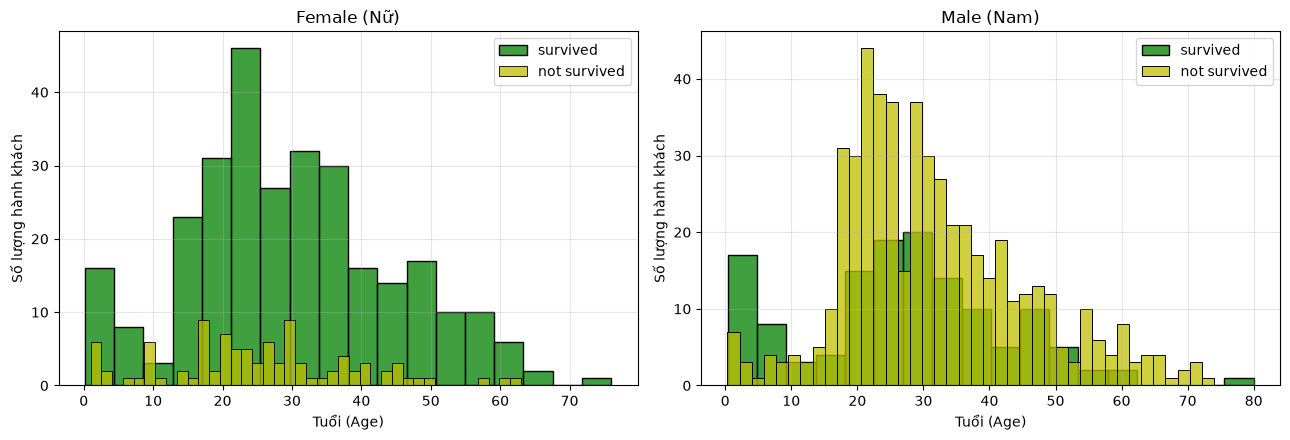

In [3]:
# Nguyễn Thành Trí - 6451071079
# Bài 1 (Trang 15-17) - Câu 3: Khảo sát Độ tuổi (age), Giới tính (sex) và Khả năng sống sót (survived)

survived = 'survived'
not_survived = 'not survived'

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 4.5))
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

# Biểu đồ cho Nữ giới
ax = sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[0], kde=False, color='g')
ax = sns.histplot(women[women['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[0], kde=False, color='y')
ax.legend()
ax.set_title('Female (Nữ)')
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Số lượng hành khách')
ax.grid(True, alpha=0.3)

# Biểu đồ cho Nam giới
ax = sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label=survived, ax=axes[1], kde=False, color='g')
ax = sns.histplot(men[men['survived'] == 0].age.dropna(), bins=40, label=not_survived, ax=axes[1], kde=False, color='y')
ax.legend()
ax.set_title('Male (Nam)')
ax.set_xlabel('Tuổi (Age)')
ax.set_ylabel('Số lượng hành khách')
ax.grid(True, alpha=0.3)

plt.tight_layout()
img_dir = get_img_dir('Phan1/Bai1')
plt.savefig(os.path.join(img_dir, 'titanic_age_sex_survived.png'), dpi=300, bbox_inches='tight')
plt.show()


### Câu 4: Khảo sát sự liên quan giữa Cổng lên tàu (`embarked`), Loại vé (`pclass`) và Khả năng sống sót (`survived`), phân biệt theo Giới tính (`sex`)
- Vẽ biểu đồ `FacetGrid` (pointplot) thể hiện tỷ lệ sống sót theo `pclass` và `sex` trên từng cổng lên tàu (`S`, `C`, `Q`).
- Vẽ biểu đồ cột phụ trợ tỷ lệ sống sót theo Hạng vé (`pclass`).

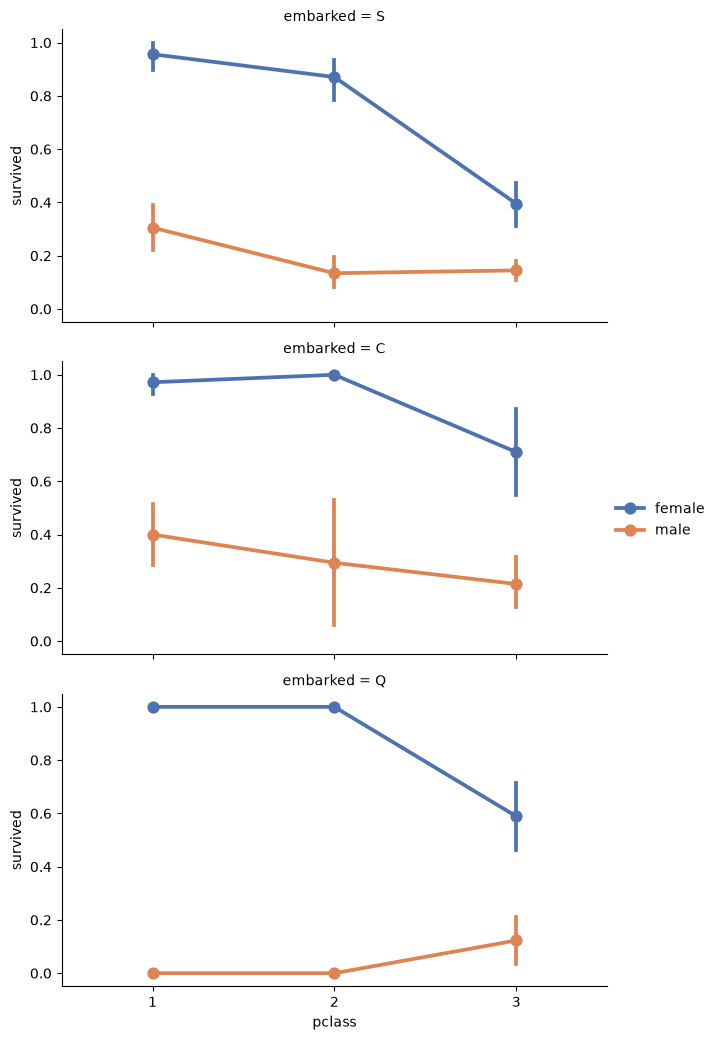

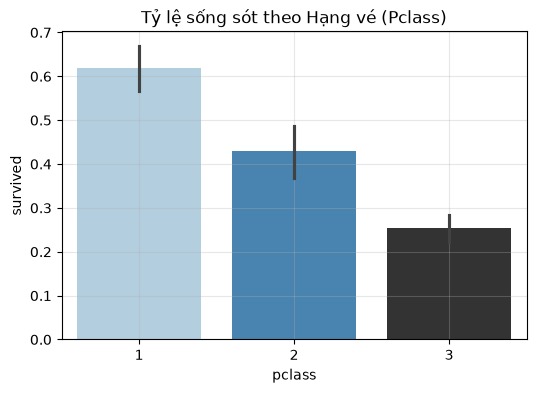

In [4]:
# Nguyễn Thành Trí - 6451071079
# Bài 1 (Trang 15-17) - Câu 4: Khảo sát Cổng lên tàu (embarked) và Loại vé (pclass) với survived

FacetGrid = sns.FacetGrid(df, row='embarked', height=3.5, aspect=1.8)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette='deep', order=[1, 2, 3], hue_order=['female', 'male'])
FacetGrid.add_legend()

img_dir = get_img_dir('Phan1/Bai1')
plt.savefig(os.path.join(img_dir, 'titanic_embarked_pclass_survived.png'), dpi=300, bbox_inches='tight')
plt.show()

# Biểu đồ tỷ lệ sống sót theo Hạng vé (pclass)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x='pclass', y='survived', data=df, ax=ax, palette='Blues_d', hue='pclass', legend=False)
ax.set_title("Tỷ lệ sống sót theo Hạng vé (Pclass)")
ax.grid(True, alpha=0.3)
plt.savefig(os.path.join(img_dir, 'titanic_pclass_survived.png'), dpi=300, bbox_inches='tight')
plt.show()


### Câu 5: Thống kê số người đi cùng và khảo sát sự liên quan với thuộc tính quyết định sống sót
- Tạo thuộc tính `relatives` = `sibsp` + `parch` (tổng số người thân đi cùng).
- Tạo thuộc tính `not_alone`: nhận `0` nếu có người đi cùng (`relatives > 0`), nhận `1` nếu đi một mình (`relatives == 0`).
- Thống kê số người đi một mình và số lượng hành khách theo số lượng người thân đi cùng.
- Vẽ biểu đồ tương quan giữa số người thân đi cùng và tỷ lệ sống sót.

Thống kê đi một mình (1: Đi một mình, 0: Có người thân đi cùng):
not_alone
1    790
0    519
Name: count, dtype: int64

Số lượng hành khách theo số lượng người thân đi cùng (relatives):
relatives
0     790
1     235
2     159
3      43
4      22
5      25
6      16
7       8
10     11
Name: count, dtype: int64


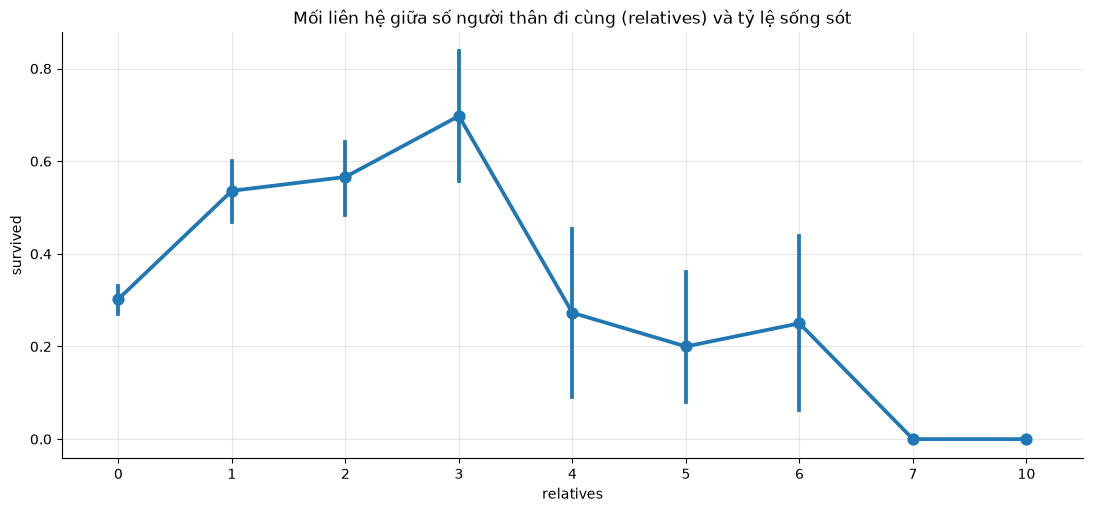

In [5]:
# Nguyễn Thành Trí - 6451071079
# Bài 1 (Trang 15-17) - Câu 5: Thống kê số người đi cùng và tương quan với survived

df['relatives'] = df['sibsp'] + df['parch']
df.loc[df['relatives'] > 0, 'not_alone'] = 0
df.loc[df['relatives'] == 0, 'not_alone'] = 1
df['not_alone'] = df['not_alone'].astype(int)

print("Thống kê đi một mình (1: Đi một mình, 0: Có người thân đi cùng):")
print(df['not_alone'].value_counts())
print("\nSố lượng hành khách theo số lượng người thân đi cùng (relatives):")
print(df['relatives'].value_counts().sort_index())

axes = sns.catplot(x='relatives', y='survived', data=df, aspect=2.2, kind='point')
plt.title("Mối liên hệ giữa số người thân đi cùng (relatives) và tỷ lệ sống sót")
plt.grid(True, alpha=0.3)
img_dir = get_img_dir('Phan1/Bai1')
plt.savefig(os.path.join(img_dir, 'titanic_relatives_survived.png'), dpi=300, bbox_inches='tight')
plt.show()


### Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xóa bỏ các thuộc tính không cần thiết
1. Trích xuất thông tin boong tàu (`deck`) từ thuộc tính `cabin`, sau đó xóa bỏ `cabin`.
2. Xóa bỏ các thuộc tính không cần thiết / gây rò rỉ nhãn: `ticket`, `boat`, `body`, `home.dest`.
3. Điền giá trị thiếu cho thuộc tính tuổi (`age`) bằng các số ngẫu nhiên trong khoảng `[mean - std, mean + std]`.
4. Điền giá trị thiếu cho thuộc tính cổng lên tàu (`embarked`) bằng giá trị xuất hiện nhiều nhất (`'S'`).
5. Điền giá trị thiếu cho thuộc tính giá vé (`fare`) nếu còn thiếu.

In [6]:
# Nguyễn Thành Trí - 6451071079
# Bài 1 (Trang 15-17) - Câu 6: Tiền xử lý thiếu dữ liệu và loại bỏ thuộc tính không cần thiết

import re

# 1. Trích xuất boong tàu (deck) từ cabin trước khi xóa cabin
deck_map = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
df['cabin'] = df['cabin'].fillna("U0")
df['deck'] = df['cabin'].map(lambda x: re.compile(r"([a-zA-Z]+)").search(x).group())
df['deck'] = df['deck'].map(deck_map).fillna(0).astype(int)
df = df.drop(['cabin'], axis=1)

# 2. Xóa các thuộc tính không cần thiết
cols_to_drop = ['ticket', 'boat', 'body', 'home.dest']
df = df.drop([c for c in cols_to_drop if c in df.columns], axis=1)

# 3. Điền giá trị thiếu cho tuổi (age) bằng số ngẫu nhiên trong [mean - std, mean + std]
mean = df["age"].mean()
std = df["age"].std()
is_null = df["age"].isnull().sum()

np.random.seed(42)
rand_age = np.random.randint(mean - std, mean + std, size=is_null)

age_slice = df["age"].copy()
age_slice[np.isnan(age_slice)] = rand_age
df["age"] = age_slice.astype(int)

# 4. Điền giá trị thiếu cho cổng lên tàu (embarked) bằng mode 'S'
df['embarked'] = df['embarked'].fillna('S')

# 5. Điền giá trị thiếu cho giá vé (fare)
df['fare'] = df['fare'].fillna(0)

print("--- KIỂM TRA LẠI SỐ LƯỢNG GIÁ TRỊ RỖNG SAU BƯỚC TIỀN XỬ LÝ ---")
print(df.isnull().sum())


--- KIỂM TRA LẠI SỐ LƯỢNG GIÁ TRỊ RỖNG SAU BƯỚC TIỀN XỬ LÝ ---
pclass       0
survived     0
name         0
sex          0
age          0
sibsp        0
parch        0
fare         0
embarked     0
relatives    0
not_alone    0
deck         0
dtype: int64


### Câu 7: Biến đổi các thuộc tính theo yêu cầu
1. Chuyển đổi thuộc tính giá vé (`fare`) về kiểu số nguyên.
2. Trích xuất thuộc tính danh hiệu (`title`) từ tên hành khách (`name`), phân loại các danh hiệu hiếm và mã hóa thành số (`Mr: 1, Miss: 2, Mrs: 3, Master: 4, Rare: 5`), sau đó xóa cột `name`.
3. Chuyển đổi thuộc tính giới tính (`sex`: male=0, female=1) và cổng lên tàu (`embarked`: S=0, C=1, Q=2) thành dạng số.
4. Chia thuộc tính tuổi (`age`) thành 8 nhóm cân bằng số phần tử theo các khoảng gợi ý.
5. Chia thuộc tính giá vé (`fare`) thành 6 nhóm theo các khoảng gợi ý.

In [7]:
# Nguyễn Thành Trí - 6451071079
# Bài 1 (Trang 15-17) - Câu 7: Biến đổi các thuộc tính

# 1. Chuyển đổi giá vé (fare) về kiểu nguyên
df['fare'] = df['fare'].astype(int)

# 2. Trích xuất danh hiệu (title) từ tên và mã hóa thành số
titles = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
df['title'] = df['name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
df['title'] = df['title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
                                   'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df['title'] = df['title'].replace('Mlle', 'Miss')
df['title'] = df['title'].replace('Ms', 'Miss')
df['title'] = df['title'].replace('Mme', 'Mrs')
df['title'] = df['title'].map(titles).fillna(0).astype(int)
df = df.drop(['name'], axis=1)

# 3. Chuyển đổi giới tính (sex) và cổng lên tàu (embarked) thành số
df['sex'] = df['sex'].map({"male": 0, "female": 1})
df['embarked'] = df['embarked'].map({"S": 0, "C": 1, "Q": 2})

# 4. Chia giá trị thuộc tính tuổi (age) thành 8 nhóm
df.loc[df['age'] <= 11, 'age'] = 0
df.loc[(df['age'] > 11) & (df['age'] <= 18), 'age'] = 1
df.loc[(df['age'] > 18) & (df['age'] <= 22), 'age'] = 2
df.loc[(df['age'] > 22) & (df['age'] <= 27), 'age'] = 3
df.loc[(df['age'] > 27) & (df['age'] <= 33), 'age'] = 4
df.loc[(df['age'] > 33) & (df['age'] <= 40), 'age'] = 5
df.loc[(df['age'] > 40) & (df['age'] <= 66), 'age'] = 6
df.loc[df['age'] > 66, 'age'] = 7

# 5. Chia giá trị thuộc tính giá vé (fare) thành 6 nhóm
df.loc[df['fare'] <= 7.91, 'fare'] = 0
df.loc[(df['fare'] > 7.91) & (df['fare'] <= 14.454), 'fare'] = 1
df.loc[(df['fare'] > 14.454) & (df['fare'] <= 31), 'fare'] = 2
df.loc[(df['fare'] > 31) & (df['fare'] <= 99), 'fare'] = 3
df.loc[(df['fare'] > 99) & (df['fare'] <= 250), 'fare'] = 4
df.loc[df['fare'] > 250, 'fare'] = 5
df['fare'] = df['fare'].astype(int)

print("--- PHÂN BỐ CÁC NHÓM TUỔI (age: 0 đến 7) ---")
print(df['age'].value_counts().sort_index())

print("\n--- PHÂN BỐ CÁC NHÓM GIÁ VÉ (fare: 0 đến 5) ---")
print(df['fare'].value_counts().sort_index())


--- PHÂN BỐ CÁC NHÓM TUỔI (age: 0 đến 7) ---
age
0     91
1    144
2    176
3    214
4    224
5    202
6    249
7      9
Name: count, dtype: int64

--- PHÂN BỐ CÁC NHÓM GIÁ VÉ (fare: 0 đến 5) ---
fare
0    361
1    312
2    325
3    227
4     67
5     17
Name: count, dtype: int64


### Câu 8: Tạo ra các thuộc tính mới
1. Thuộc tính tuổi * loại vé (`age_class`): tích của tuổi (`age`) và loại vé (`pclass`).
2. Thuộc tính giá vé trên mỗi người (`fare_per_person`): giá vé chia cho số người đi cùng (có làm trơn + 1): `fare / (relatives + 1)`.
3. Hiển thị 10 dòng đầu tiên và thông tin cấu trúc dữ liệu sau khi hoàn tất tiền xử lý và biến đổi.

In [8]:
# Nguyễn Thành Trí - 6451071079
# Bài 1 (Trang 15-17) - Câu 8: Tạo ra các thuộc tính mới

# 1. Thuộc tính tuổi * loại vé (age_class)
df['age_class'] = df['age'] * df['pclass']

# 2. Thuộc tính giá vé trên mỗi người (fare_per_person)
df['fare_per_person'] = (df['fare'] / (df['relatives'] + 1)).astype(int)

# Hiển thị 10 dòng đầu tiên
print("--- 10 DÒNG ĐẦU TIÊN CỦA BẢNG DỮ LIỆU HOÀN THIỆN ---")
display(df.head(10))

# Thông tin cấu trúc dữ liệu cuối cùng
print("\n--- THÔNG TIN CẤU TRÚC DỮ LIỆU CUỐI CÙNG (df.info()) ---")
df.info()


--- 10 DÒNG ĐẦU TIÊN CỦA BẢNG DỮ LIỆU HOÀN THIỆN ---


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_class,fare_per_person
0,1,1,1,4,0,0,4,0,0,1,2,2,4,4
1,1,1,0,0,1,2,4,0,3,0,3,4,0,1
2,1,0,1,0,1,2,4,0,3,0,3,2,0,1
3,1,0,0,4,1,2,4,0,3,0,3,1,4,1
4,1,0,1,3,1,2,4,0,3,0,3,3,3,1
5,1,1,0,6,0,0,2,0,0,1,5,1,6,2
6,1,1,1,6,1,0,3,0,1,0,4,2,6,1
7,1,0,0,5,0,0,0,0,0,1,1,1,5,0
8,1,1,1,6,2,0,3,0,2,0,3,3,6,1
9,1,0,0,7,0,0,3,1,0,1,8,1,7,3



--- THÔNG TIN CẤU TRÚC DỮ LIỆU CUỐI CÙNG (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   pclass           1309 non-null   int64
 1   survived         1309 non-null   int64
 2   sex              1309 non-null   int64
 3   age              1309 non-null   int64
 4   sibsp            1309 non-null   int64
 5   parch            1309 non-null   int64
 6   fare             1309 non-null   int64
 7   embarked         1309 non-null   int64
 8   relatives        1309 non-null   int64
 9   not_alone        1309 non-null   int64
 10  deck             1309 non-null   int64
 11  title            1309 non-null   int64
 12  age_class        1309 non-null   int64
 13  fare_per_person  1309 non-null   int64
dtypes: int64(14)
memory usage: 143.3 KB
